# Grid Search Results:

In [3]:
import numpy as np
import random
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
# Hyperparameters we selected

e_c_grid = [(theta, alpha, gamma, epsilon)
        for theta in [1e-6, 5e-6, 1e-5, 5e-5, 1e-4]
        for alpha in [0.0001, 0.0005, 0.001, 0.005, 0.01]
        for gamma in [0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 1]
        for epsilon in [0.01, 0.02, 0.05, 0.1, 0.2]]

a_r_grid = [(theta, alpha, beta, epsilon)
        for theta in [1e-6, 5e-6, 1e-5, 5e-5, 1e-4]
        for alpha in [0.0001, 0.0005, 0.001, 0.005, 0.01]
        for beta in [0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1, 0.5]
        for epsilon in [0.01, 0.02, 0.05, 0.1, 0.2]]

seeds = [23, 11, 1999, 5, 476]

k = 11
n = int(k*(k-1)/2)
max_it = 50000

In [6]:
Names = ["Episodic_UM_R",
        "Episodic_M_R",
        "Episodic_UR",
        "Incremental_UM_R",
        "Incremental_M_R",
        "Incremental_UR",
        "Monotonic_Episodic_UR",
        "Monotonic_Incremental_UR",
        "Continuing_UM_R",
        "Continuing_M_R",
        "Continuing_UR",
        "Average_reward_UM_R",
        "Average_reward_M_R",
        "Average_reward_UR"]

N = { "Episodic_UM_R" : 0,
      "Episodic_M_R" : 1,
      "Episodic_UR" : 2,
      "Incremental_UM_R" : 3,
      "Incremental_M_R" : 4,
      "Incremental_UR" : 5,
      "Monotonic_Episodic_UR" : 6,
      "Monotonic_Incremental_UR" : 7,
      "Continuing_UM_R" : 8,
      "Continuing_M_R" : 9,
      "Continuing_UR" : 10,
      "Average_reward_UM_R" : 11,
      "Average_reward_M_R" : 12,
      "Average_reward_UR" : 13,
    }

GS = []

for name in Names:
  path = name + ".csv"
  A = pd.read_csv(path)
  GS.append(A)

In [7]:
GS_seed_average = []

grid = e_c_grid
for i in range(11):
    df = GS[i]
    a = [(0.0, 0.0, 0.0, 0.0) for (theta, alpha, gamma, epsilon) in grid]
    A = pd.DataFrame(a,
                   index = list(grid),
                   columns=['a_d', 'r_d', 'w_b', 'n_it'])

    for (theta, alpha, gamma, epsilon) in grid:
      avg_a_d = np.mean(df.loc[(df['theta'] == theta) & (df['alpha'] == alpha) & (df['gamma'] == gamma) & (df['epsilon'] == epsilon), ['a_d']])
      avg_r_d = np.mean(df.loc[(df['theta'] == theta) & (df['alpha'] == alpha) & (df['gamma'] == gamma) & (df['epsilon'] == epsilon), ['r_d']])
      avg_w_b = np.mean(df.loc[(df['theta'] == theta) & (df['alpha'] == alpha) & (df['gamma'] == gamma) & (df['epsilon'] == epsilon), ['w_b']])
      avg_n_it = np.mean(df.loc[(df['theta'] == theta) & (df['alpha'] == alpha) & (df['gamma'] == gamma) & (df['epsilon'] == epsilon), ['n_it']])
      A.at[(theta, alpha, gamma, epsilon), 'a_d'] = avg_a_d
      A.at[(theta, alpha, gamma, epsilon), 'r_d'] = avg_r_d
      A.at[(theta, alpha, gamma, epsilon), 'w_b'] = avg_w_b
      A.at[(theta, alpha, gamma, epsilon), 'n_it'] = avg_n_it

    GS_seed_average.append(A)

grid = a_r_grid
for i in range(11,14):
    df = GS[i]
    a = [(0.0, 0.0, 0.0, 0.0) for (theta, alpha, beta, epsilon) in grid]
    A = pd.DataFrame(a,
                   index = list(grid),
                   columns=['a_d', 'r_d', 'w_b', 'n_it'])

    for (theta, alpha, beta, epsilon) in grid:
      avg_a_d = np.mean(df.loc[(df['theta'] == theta) & (df['alpha'] == alpha) & (df['beta'] == beta) & (df['epsilon'] == epsilon), ['a_d']])
      avg_r_d = np.mean(df.loc[(df['theta'] == theta) & (df['alpha'] == alpha) & (df['beta'] == beta) & (df['epsilon'] == epsilon), ['r_d']])
      avg_w_b = np.mean(df.loc[(df['theta'] == theta) & (df['alpha'] == alpha) & (df['beta'] == beta) & (df['epsilon'] == epsilon), ['w_b']])
      avg_n_it = np.mean(df.loc[(df['theta'] == theta) & (df['alpha'] == alpha) & (df['beta'] == beta) & (df['epsilon'] == epsilon), ['n_it']])
      A.at[(theta, alpha, beta, epsilon), 'a_d'] = avg_a_d
      A.at[(theta, alpha, beta, epsilon), 'r_d'] = avg_r_d
      A.at[(theta, alpha, beta, epsilon), 'w_b'] = avg_w_b
      A.at[(theta, alpha, beta, epsilon), 'n_it'] = avg_n_it

    GS_seed_average.append(A)

In [8]:
good_param = pd.DataFrame(np.zeros(14), index = Names, columns=['n_good_param'])
best_result = pd.DataFrame(np.zeros(14), index = Names, columns=['best_result'])

for name in Names:
  df = GS_seed_average[N[name]][['r_d', 'w_b', 'n_it']]
  q = GS_seed_average[N[name]]['r_d']
  min = np.min(q)

  print("--Results for "+name+"--")
  with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    print("\n-Parameters within 1% of the actual minimum:\n")
    good = df.loc[q < 0.01]
    best = df.loc[q == min]
    print(good)
    print("\n-Number of parameters within 1% of the actual minimum:\n")
    good_n = good.shape[0]
    good_param.loc[name] = good_n
    print(good_n)
    print("\n-Number of good runs that converged early:\n")
    print(len(good.loc[(good['n_it'] < max_it)]))
    print("\n-Absolute best hyperparameters:\n")
    best_result.loc[name] = best['r_d'].iloc[0]
    print(best)
    print("\n\n")

--Results for Episodic_UM_R--

-Parameters within 1% of the actual minimum:

Empty DataFrame
Columns: [r_d, w_b, n_it]
Index: []

-Number of parameters within 1% of the actual minimum:

0

-Number of good runs that converged early:

0

-Absolute best hyperparameters:

                              r_d  w_b     n_it
(1e-06, 0.001, 0.8, 0.2)  0.04352  4.8  50000.0



--Results for Episodic_M_R--

-Parameters within 1% of the actual minimum:

                               r_d  w_b     n_it
(1e-06, 0.01, 0.9, 0.2)   0.007496  2.6  50000.0
(1e-06, 0.01, 0.95, 0.2)  0.009846  3.0  50000.0
(5e-06, 0.01, 0.9, 0.2)   0.007496  2.6  50000.0
(5e-06, 0.01, 0.95, 0.2)  0.009846  3.0  50000.0
(1e-05, 0.01, 0.9, 0.2)   0.007496  2.6  50000.0
(1e-05, 0.01, 0.95, 0.2)  0.009846  3.0  50000.0

-Number of parameters within 1% of the actual minimum:

6

-Number of good runs that converged early:

0

-Absolute best hyperparameters:

                              r_d  w_b     n_it
(1e-06, 0.01, 0.9, 0.2)  

In [9]:
print(good_param)
print('\n')
print(best_result)

                          n_good_param
Episodic_UM_R                      0.0
Episodic_M_R                       6.0
Episodic_UR                        0.0
Incremental_UM_R                   0.0
Incremental_M_R                    0.0
Incremental_UR                     0.0
Monotonic_Episodic_UR              0.0
Monotonic_Incremental_UR           0.0
Continuing_UM_R                   51.0
Continuing_M_R                     3.0
Continuing_UR                      0.0
Average_reward_UM_R               10.0
Average_reward_M_R                42.0
Average_reward_UR                  0.0


                          best_result
Episodic_UM_R                0.043520
Episodic_M_R                 0.007496
Episodic_UR                  0.124276
Incremental_UM_R             0.083090
Incremental_M_R              0.048182
Incremental_UR               0.210772
Monotonic_Episodic_UR        0.029214
Monotonic_Incremental_UR     0.310504
Continuing_UM_R              0.000136
Continuing_M_R               0.00

In [10]:
gp = pd.concat([good_param.iloc[0:6], good_param.iloc[8:14]])
gp = pd.DataFrame(gp.values.reshape(4, 3),
                  index = ['Episodic', 'Incremental', 'Continuing', 'Average Reward'],
                  columns = ['UM_R', 'M_R', 'UR'])
print(gp)
print('\n')
br = pd.concat([best_result.iloc[0:6], best_result.iloc[8:14]])
br = pd.DataFrame(br.values.reshape(4, 3),
                  index = ['Episodic', 'Incremental', 'Continuing', 'Average Reward'],
                  columns = ['UM_R', 'M_R', 'UR'])
print(br)

                UM_R   M_R   UR
Episodic         0.0   6.0  0.0
Incremental      0.0   0.0  0.0
Continuing      51.0   3.0  0.0
Average Reward  10.0  42.0  0.0


                    UM_R       M_R        UR
Episodic        0.043520  0.007496  0.124276
Incremental     0.083090  0.048182  0.210772
Continuing      0.000136  0.008670  0.016136
Average Reward  0.005246  0.003996  0.120410


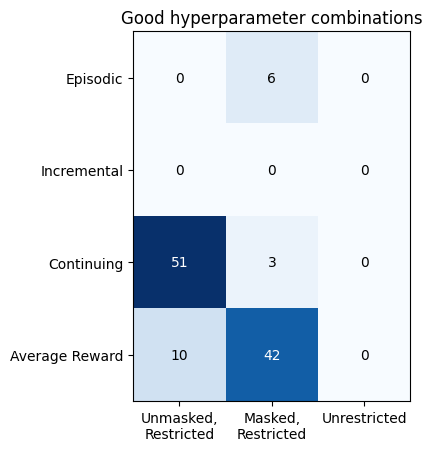

<Figure size 640x480 with 0 Axes>

In [11]:
fig, ax = plt.subplots()
im = ax.imshow(gp, cmap='Blues')
# im = ax.imshow(gp, cmap='Greys', vmin=0, vmax=65)

names = ['Episodic', 'Incremental', 'Continuing', 'Average Reward']
settings = ['Unmasked,\nRestricted', 'Masked,\nRestricted', 'Unrestricted']

# Show all ticks and label them with the respective list entries
ax.set_xticks(range(len(settings)), labels=settings)
ax.set_yticks(range(len(names)), labels=names)

# Loop over data dimensions and create text annotations.
for i in range(len(names)):
    for j in range(len(settings)):
        color = "k" if gp.iloc[i, j] < 40 else "w"
        text = ax.text(j, i, int(gp.iloc[i, j]),
                       ha="center", va="center", color=color)

ax.set_title("Good hyperparameter combinations")
plt.show()
plt.savefig("num_hyp_001.svg")

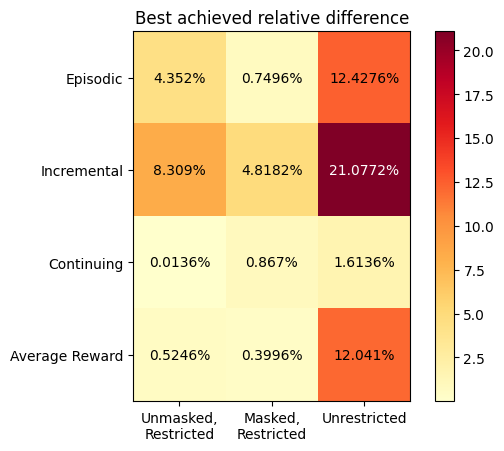

<Figure size 640x480 with 0 Axes>

In [12]:
br2 = round(100*br, 4)
fig, ax = plt.subplots()
im = ax.imshow(br2, cmap = 'YlOrRd')
# im = ax.imshow(br2, cmap = 'RdYlGn_r')

cbar = ax.figure.colorbar(im, ax=ax)

names = ['Episodic', 'Incremental', 'Continuing', 'Average Reward']
settings = ['Unmasked,\nRestricted', 'Masked,\nRestricted', 'Unrestricted']

# Show all ticks and label them with the respective list entries
ax.set_xticks(range(len(settings)), labels=settings)
ax.set_yticks(range(len(names)), labels=names)

# Loop over data dimensions and create text annotations.
for i in range(len(names)):
    for j in range(len(settings)):
        color = "k" if br2.iloc[i, j] < 20 else "w"
        text = ax.text(j, i, str(br2.iloc[i, j])+'%',
                       ha="center", va="center", color=color)

ax.set_title("Best achieved relative difference")
plt.show()
plt.savefig("best_rel_diff.svg")

# Chosen method - parameter combos:

```
Episodic_M_R: (1e-06, 0.01, 0.9, 0.2)

Continuing_UM_R: (1e-06, 0.0005, 0.8, 0.2)

Average_Reward_UM_R: (1e-06, 0.001, 0.0001, 0.2)

Average_Reward_M_R: (1e-06, 0.005, 0.0005, 0.2)
```

